In [1]:

from pathlib import Path
from dataclasses import dataclass, asdict
import math
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, differential_evolution
from scipy.stats import pearsonr

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# ------------------------------------------------------------------
# LOCAL PROJECT PATHS
# ------------------------------------------------------------------
# Run the notebook from your project folder.
# Example:
# Gieskus_Model/
#   paper4_ethixo_giesekus_research_framework_FINAL.ipynb
#   data/paper4/*.xlsx
#   results/paper4/
PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data" / "paper4"
RESULTS_ROOT = PROJECT_ROOT / "results" / "paper4"

DATA_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Data root    :", DATA_ROOT)
print("Results root :", RESULTS_ROOT)

try:
    import openpyxl
    print("openpyxl     : available")
except ImportError:
    print("openpyxl     : NOT installed")
    print("Run this in a new cell if you need to read .xlsx files:")
    print("%pip install openpyxl")


Project root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model
Data root    : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4
Results root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\results\paper4
openpyxl     : available


In [2]:
# Parameters from paper
physiology = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "HCT_percent": [42.9, 46.2, 38.3, 45.2, 43.1],
    "Fibrinogen_mg_dl": [0.242, 0.316, 0.333, 0.214, 0.249],
    "Total_cholesterol_mg_ml": [138, 132, 145, 187, 244],
    "Triglycerides_mg_ml": [108, 111, 144, 57, 94],
    "HDL_mg_ml": [35, 41, 39, 65, 70],
    "LDL_mg_ml": [83, 72, 82, 108, 154],
})

reported_params = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "eta0": [0.0051, 0.0080, 0.0047, 0.0048, 0.0075],
    "eta_s": [0.0031, 0.0036, 0.0030, 0.0035, 0.0034],
    "eta_p": [0.0020, 0.0044, 0.0018, 0.0013, 0.0041],
    "lambda1": [0.0270, 0.2133, 0.3982, 0.0187, 0.2956],
    "lambda2": [0.0164, 0.0955, 0.2491, 0.0135, 0.1339],
    "alpha": [0.3068, 0.0062, 0.0005, 0.1922, 0.0057],
    "tr1": [0.5081, 0.3063, 0.4531, 0.3016, 0.5618],
    "tr2": [0.1126, 0.0240, 0.2038, 0.1351, 0.0035],
    "muR": [0.0181, 0.0275, 0.0217, 0.0179, 0.0487],
    "tau_y0": [0.0027, 0.0022, 0.0021, 0.0030, 0.0037],
    "m": [1.2812, 1.9355, 1.8814, 1.4506, 1.6370],
    "tau_beta": [0.61, 1.13, 1.67, 0.65, 0.5921],
    "G_R": [0.25, 0.77, 0.43, 0.28, 0.5362],
    "gamma0_R": [1, 1, 1, 1, 1],
    "Fcost_SS": [0.0037, 0.0187, 0.0052, 0.0109, 0.0221],
    "Fcost_trans": [0.00056, 0.00072, 0.00051, 0.00048, 0.00122],
})

display(physiology)
display(reported_params)


,Donor,HCT_percent,Fibrinogen_mg_dl,Total_cholesterol_mg_ml,Triglycerides_mg_ml,HDL_mg_ml,LDL_mg_ml
0,1,42.9,0.242,138,108,35,83
1,2,46.2,0.316,132,111,41,72
2,3,38.3,0.333,145,144,39,82
3,4,45.2,0.214,187,57,65,108
4,5,43.1,0.249,244,94,70,154


,Donor,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R,gamma0_R,Fcost_SS,Fcost_trans
0,1,0.0051,0.0031,0.0020,0.0270,0.0164,0.3068,0.5081,0.1126,0.0181,0.0027,1.2812,0.6100,0.2500,1,0.0037,0.00056
1,2,0.0080,0.0036,0.0044,0.2133,0.0955,0.0062,0.3063,0.0240,0.0275,0.0022,1.9355,1.1300,0.7700,1,0.0187,0.00072
2,3,0.0047,0.0030,0.0018,0.3982,0.2491,0.0005,0.4531,0.2038,0.0217,0.0021,1.8814,1.6700,0.4300,1,0.0052,0.00051
3,4,0.0048,0.0035,0.0013,0.0187,0.0135,0.1922,0.3016,0.1351,0.0179,0.0030,1.4506,0.6500,0.2800,1,0.0109,0.00048
4,5,0.0075,0.0034,0.0041,0.2956,0.1339,0.0057,0.5618,0.0035,0.0487,0.0037,1.6370,0.5921,0.5362,1,0.0221,0.00122


In [3]:

@dataclass
class EthixoGiesekusParams:
    eta0: float
    eta_s: float
    eta_p: float
    lambda1: float
    lambda2: float
    alpha: float
    tr1: float
    tr2: float
    muR: float
    tau_y0: float
    m: float
    tau_beta: float
    G_R: float
    gamma0_R: float = 1.0

def params_for_donor(donor=1):
    row = reported_params.loc[reported_params["Donor"] == donor].iloc[0]
    return EthixoGiesekusParams(
        eta0=float(row.eta0),
        eta_s=float(row.eta_s),
        eta_p=float(row.eta_p),
        lambda1=float(row.lambda1),
        lambda2=float(row.lambda2),
        alpha=float(row.alpha),
        tr1=float(row.tr1),
        tr2=float(row.tr2),
        muR=float(row.muR),
        tau_y0=float(row.tau_y0),
        m=float(row.m),
        tau_beta=float(row.tau_beta),
        G_R=float(row.G_R),
        gamma0_R=float(row.gamma0_R),
    )

P1 = params_for_donor(1)
print(P1)


EthixoGiesekusParams(eta0=0.0051, eta_s=0.0031, eta_p=0.002, lambda1=0.027, lambda2=0.0164, alpha=0.3068, tr1=0.5081, tr2=0.1126, muR=0.0181, tau_y0=0.0027, m=1.2812, tau_beta=0.61, G_R=0.25, gamma0_R=1.0)


In [4]:

PAPER_TARGETS_DONOR1 = {
    "Fcost_SS": 0.0037,
    "Fcost_trans": 0.00056,
    "n_SS": 16,
    "RSS_SS": 0.004,
    "AIC_SS": 10.72,
    "BIC_SS": 49.72,
    "n_trans": 390,
    "RSS_trans": 0.047,
    "AIC_trans": 19.89,
    "BIC_trans": 149.01,
}
pd.Series(PAPER_TARGETS_DONOR1, name="Paper Donor 1 target")


Fcost_SS         0.00370
Fcost_trans      0.00056
n_SS            16.00000
RSS_SS           0.00400
AIC_SS          10.72000
BIC_SS          49.72000
n_trans        390.00000
RSS_trans        0.04700
AIC_trans       19.89000
BIC_trans      149.01000
Name: Paper Donor 1 target, dtype: float64

In [5]:

SUPPORTED_SUFFIXES = {".xlsx", ".xls", ".csv", ".txt", ".dat", ".tsv"}

def discover_data_files(root=DATA_ROOT):
    root = Path(root)
    rows = []

    if not root.exists():
        return pd.DataFrame(columns=["filename", "path", "suffix", "size_MB"])

    for file_path in sorted(root.rglob("*")):
        if file_path.is_file() and file_path.suffix.lower() in SUPPORTED_SUFFIXES:
            rows.append({
                "filename": file_path.name,
                "path": file_path,
                "suffix": file_path.suffix.lower(),
                "size_MB": file_path.stat().st_size / (1024**2),
            })

    return pd.DataFrame(rows)

files = discover_data_files()

print("Searching:", DATA_ROOT)
if files.empty:
    print("No supported data files found.")
else:
    print(f"Found {len(files)} file(s).")
    display(files)


Searching: c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4
Found 2 file(s).


,filename,path,suffix,size_MB
0,JUN18.xlsx,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,1.637993
1,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,3.209073


In [6]:

def read_file_tables(path):
    """Read one local file into a dictionary of raw DataFrames.

    Excel sheets use header=None so ARES-G2 metadata and unusual header
    positions are preserved for inspection.
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(path)

    suffix = path.suffix.lower()

    if suffix in {".xlsx", ".xls"}:
        engine = "openpyxl" if suffix == ".xlsx" else None
        book = pd.ExcelFile(path, engine=engine)
        return {
            f"{path.name}::{sheet}": pd.read_excel(
                path,
                sheet_name=sheet,
                header=None,
                engine=engine,
            )
            for sheet in book.sheet_names
        }

    if suffix == ".csv":
        return {path.name: pd.read_csv(path, header=None)}

    if suffix == ".tsv":
        return {path.name: pd.read_csv(path, sep="\t", header=None)}

    if suffix in {".txt", ".dat"}:
        return {path.name: pd.read_csv(path, sep=None, engine="python", header=None)}

    raise ValueError(f"Unsupported file type: {suffix}")

def load_all_tables(root=DATA_ROOT):
    all_tables = {}
    errors = []
    inventory = discover_data_files(root)

    for path in inventory.get("path", []):
        try:
            all_tables.update(read_file_tables(path))
        except Exception as exc:
            errors.append({"path": str(path), "error": str(exc)})

    return all_tables, pd.DataFrame(errors)

def raw_sheet_profile(name, df):
    nonempty = int(df.notna().sum().sum())
    total = max(df.shape[0] * df.shape[1], 1)
    numeric = int(df.apply(pd.to_numeric, errors="coerce").notna().sum().sum())

    return {
        "table": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "nonempty_cells": nonempty,
        "nonempty_fraction": nonempty / total,
        "numeric_fraction_of_all_cells": numeric / total,
    }

RAW_TABLES, LOAD_ERRORS = load_all_tables(DATA_ROOT)

if RAW_TABLES:
    raw_inventory = pd.DataFrame(
        [raw_sheet_profile(name, df) for name, df in RAW_TABLES.items()]
    ).sort_values("table").reset_index(drop=True)
    print(f"Successfully loaded {len(RAW_TABLES)} sheet/table(s).")
    display(raw_inventory)
else:
    raw_inventory = pd.DataFrame()
    if files.empty:
        print("No data files were found.")
    else:
        print("Files were found, but no tables could be loaded.")

if not LOAD_ERRORS.empty:
    print("\nLoad errors:")
    display(LOAD_ERRORS)


Successfully loaded 18 sheet/table(s).


,table,rows,cols,nonempty_cells,nonempty_fraction,numeric_fraction_of_all_cells
0,JUN18.xlsx::Cessation,50,34,1235,0.726471,0.691176
1,JUN18.xlsx::Helton,542,107,28951,0.499207,0.495793
2,JUN18.xlsx::LAOS,2008,73,110065,0.750866,0.750027
3,JUN18.xlsx::SRFS,272,23,4884,0.780691,0.773977
4,JUN18.xlsx::Steady State & SAOS,29,19,354,0.642468,0.591652
5,JUN18.xlsx::Step Up Step Down,4189,69,20250,0.070059,0.069623
6,JUN18.xlsx::UDLAOS,1507,17,14006,0.546704,0.545533
7,JUN18.xlsx::reversal,303,23,3279,0.470512,0.464916
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308


In [7]:

EXPERIMENT_KEYWORDS = {
    "UD-LAOS": ["udlaos", "ud-laos", "unidirectional"],
    "LAOS": ["laos"],
    "SAOS": ["saos", "amplitude sweep", "frequency sweep", "amp sweep", "freq sweep"],
    "STEP": ["step", "step up", "step down"],
    "STEADY_STATE": ["steady", "steady state", " ss "],
    "TRIANGLE_RAMP": ["triangle", "ramp"],
    "HELTON_OR_OTHER": ["helton"],
}

def infer_experiment_type(text):
    t = f" {str(text).lower()} "
    for exp, keywords in EXPERIMENT_KEYWORDS.items():
        if any(keyword in t for keyword in keywords):
            return exp
    return "UNKNOWN"

def classify_loaded_tables(raw_tables=RAW_TABLES):
    return pd.DataFrame([
        {
            "table": name,
            "experiment_guess": infer_experiment_type(name),
            "rows": df.shape[0],
            "cols": df.shape[1],
        }
        for name, df in raw_tables.items()
    ])

if RAW_TABLES:
    display(classify_loaded_tables())


,table,experiment_guess,rows,cols
0,JUN18.xlsx::Steady State & SAOS,SAOS,29,19
1,JUN18.xlsx::Helton,HELTON_OR_OTHER,542,107
2,JUN18.xlsx::Step Up Step Down,STEP,4189,69
3,JUN18.xlsx::LAOS,LAOS,2008,73
4,JUN18.xlsx::reversal,UNKNOWN,303,23
5,JUN18.xlsx::Cessation,UNKNOWN,50,34
6,JUN18.xlsx::SRFS,UNKNOWN,272,23
7,JUN18.xlsx::UDLAOS,UD-LAOS,1507,17
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,29,46
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,2008,67


In [8]:

def tidy_from_raw(raw_df, header_row, drop_empty=True):
    header = raw_df.iloc[header_row].astype(str).str.strip()
    df = raw_df.iloc[header_row + 1:].copy()
    df.columns = header

    if drop_empty:
        df = df.dropna(how="all").dropna(axis=1, how="all")

    df = df.reset_index(drop=True)

    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        nonmissing = df[col].notna().sum()
        numeric_nonmissing = converted.notna().sum()

        if nonmissing > 0 and numeric_nonmissing / nonmissing >= 0.8:
            df[col] = converted

    return df

def profile_tidy_dataframe(df):
    overview = {
        "rows": len(df),
        "cols": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "numeric_cols": int(df.select_dtypes(include=np.number).shape[1]),
        "non_numeric_cols": int(df.select_dtypes(exclude=np.number).shape[1]),
    }

    columns = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_n": df.isna().sum(),
        "missing_pct": 100 * df.isna().mean(),
        "unique_n": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

    return overview, columns

def numeric_summary(df):
    num = df.select_dtypes(include=np.number)
    if num.empty:
        return pd.DataFrame()

    quantiles = num.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
    quantiles.columns = [f"q{int(q*100):02d}" for q in quantiles.columns]

    base = num.agg(["count", "mean", "std", "min", "max"]).T
    return base.join(quantiles)

def plot_numeric_distributions(df, max_cols=12, bins=30):
    num = df.select_dtypes(include=np.number)

    for col in list(num.columns[:max_cols]):
        values = num[col].dropna().to_numpy()
        if len(values) == 0:
            continue

        plt.figure(figsize=(7, 4))
        plt.hist(values, bins=bins)
        plt.xlabel(str(col))
        plt.ylabel("Count")
        plt.title(f"Distribution: {col}")
        plt.tight_layout()
        plt.show()


Equation 13


In [9]:

def beta_ss(gdot, p):
    g = np.abs(np.asarray(gdot, dtype=float))
    return (p.tr2 * np.sqrt(g) + 1.0) / (
        p.tr1 * g + p.tr2 * np.sqrt(g) + 1.0
    )


In [10]:
#Geisekus Backbone
def giesekus_eta_ss(gdot, p, eps=1e-14):
    g = np.abs(np.asarray(gdot, dtype=float))
    lam1 = p.lambda1
    lam2 = p.lambda2
    alpha = p.alpha

    A = alpha * (1.0 - alpha) * (lam1 * g) ** 2
    chi2 = np.ones_like(g, dtype=float)

    mask = np.abs(A) > eps
    chi2[mask] = (
        np.sqrt(1.0 + 16.0 * A[mask]) - 1.0
    ) / (8.0 * A[mask])

    chi2 = np.maximum(chi2, 0.0)
    chi = np.sqrt(chi2)

    f = (1.0 - chi) / (1.0 + (1.0 - 2.0 * alpha) * chi)

    ratio = (
        lam2 / lam1
        + (1.0 - lam2 / lam1)
        * ((1.0 - f) / (1.0 + (1.0 - 2.0 * alpha) * f))
    )

    return p.eta0 * ratio

def tau_ve_ss(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    return giesekus_eta_ss(gdot, p) * gdot


In [11]:

def steady_total_stress_as_printed(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return tau_ve_ss(gdot, p) + p.muR * beta**p.m + p.tau_y0 * beta

def steady_total_stress_dimensional(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return (
        tau_ve_ss(gdot, p)
        + p.muR * beta**p.m * gdot
        + p.tau_y0 * beta
    )


In [12]:

def plastic_shear_rate(imposed_gdot, beta, gamma_e, p, eps=1e-12):
    beta_safe = float(np.clip(beta, eps, 1.0))
    gamma_max = p.gamma0_R * beta_safe

    if imposed_gdot >= 0:
        denom = 2.0 - gamma_e / gamma_max
    else:
        denom = 2.0 + gamma_e / gamma_max

    if abs(denom) < eps:
        denom = eps if denom >= 0 else -eps

    return imposed_gdot / denom

def rouleaux_rhs(t, y, imposed_gdot, p):
    beta, gamma_e, tau_r_ve = y

    beta_safe = float(np.clip(beta, 1e-10, 1.0))
    gamma_max = p.gamma0_R * beta_safe
    gdot_p = plastic_shear_rate(imposed_gdot, beta_safe, gamma_e, p)

    beta_dot = (
        -p.tr1 * beta_safe * abs(gdot_p)
        + p.tr2 * (1.0 - beta_safe) * np.sqrt(abs(gdot_p))
        + (1.0 - beta_safe)
    ) / p.tau_beta

    gamma_max_dot = p.gamma0_R * beta_dot

    gamma_e_dot = gdot_p - (gamma_e / gamma_max) * abs(gdot_p)
    if gamma_max_dot < 0:
        gamma_e_dot += (gamma_e / gamma_max) * gamma_max_dot

    structural_visc_denom = max(p.muR * beta_safe**p.m, 1e-14)

    tau_r_ve_dot = p.G_R * beta_safe**p.m * (
        gdot_p - tau_r_ve / structural_visc_denom
    )

    if beta_dot < 0:
        tau_r_ve_dot += p.m * (tau_r_ve / beta_safe) * beta_dot

    return [beta_dot, gamma_e_dot, tau_r_ve_dot]

def tau_r_elastic_as_printed(beta, p):
    return (p.tau_y0 / p.gamma0_R) * np.asarray(beta, dtype=float)

def simulate_rouleaux_step(initial_gdot, final_gdot, p=P1, t_end=60.0, n=800):
    beta0 = float(beta_ss(initial_gdot, p))
    gamma_e0 = p.gamma0_R * beta0
    tau_r_ve0 = p.muR * beta0**p.m * initial_gdot

    positive_times = np.logspace(-4, np.log10(t_end), n)
    t_eval = np.unique(np.concatenate(([0.0], positive_times)))

    sol = solve_ivp(
        lambda t, y: rouleaux_rhs(t, y, final_gdot, p),
        (0.0, t_end),
        [beta0, gamma_e0, tau_r_ve0],
        t_eval=t_eval,
        method="LSODA",
        rtol=1e-8,
        atol=1e-10,
    )

    if not sol.success:
        warnings.warn(sol.message)

    out = pd.DataFrame({
        "time_s": sol.t,
        "beta": np.clip(sol.y[0], 0, 1),
        "gamma_e": sol.y[1],
        "tau_r_ve_Pa": sol.y[2],
    })

    out["tau_r_e_Pa_as_printed"] = tau_r_elastic_as_printed(out["beta"], p)
    out["tau_rouleaux_Pa"] = out["tau_r_ve_Pa"] + out["tau_r_e_Pa_as_printed"]
    out["initial_gdot_s-1"] = initial_gdot
    out["final_gdot_s-1"] = final_gdot

    return out


In [13]:
#Validation
def make_validation_row(stage, check, calculated, paper_target, tolerance, notes=""):
    if pd.isna(calculated) or pd.isna(paper_target):
        status = "PENDING"
        difference = np.nan
    else:
        difference = float(calculated - paper_target)
        status = "PASS" if abs(difference) <= tolerance else "FAIL"

    return {
        "stage": stage,
        "check": check,
        "calculated": calculated,
        "paper_or_expected_target": paper_target,
        "absolute_difference": abs(difference) if np.isfinite(difference) else np.nan,
        "tolerance": tolerance,
        "status": status,
        "notes": notes,
    }

def validate_parameter_identities(p=P1):
    rows = []

    rows.append(make_validation_row(
        "A — parameters",
        "eta0 = eta_s + eta_p",
        p.eta_s + p.eta_p,
        p.eta0,
        5e-5,
        "Uses rounded values printed in the paper."
    ))

    lambda2_from_relation = p.lambda1 * p.eta_s / (p.eta_s + p.eta_p)

    rows.append(make_validation_row(
        "A — parameters",
        "lambda2 relation",
        lambda2_from_relation,
        p.lambda2,
        5e-4,
        "Small discrepancy is acceptable because the paper parameters are rounded."
    ))

    return pd.DataFrame(rows)

parameter_validation = validate_parameter_identities()
display(parameter_validation)


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,A — parameters,eta0 = eta_s + eta_p,0.005100,0.0051,0.000000,0.00005,PASS,Uses rounded values printed in the paper.
1,A — parameters,lambda2 relation,0.016412,0.0164,0.000012,0.00050,PASS,Small discrepancy is acceptable because the pa...


In [14]:

EQ13_CHECKPOINTS_DONOR1 = pd.DataFrame({
    "shear_rate_s-1": [0, 0.1, 0.25, 0.5, 1, 2.5, 5, 10, 100],
    "expected_beta_ss": [
        1.0000000000,
        0.9532315966,
        0.8926541736,
        0.8095106305,
        0.6864934905,
        0.4811676906,
        0.3300866076,
        0.2106660243,
        0.0401617047,
    ],
})

EQ13_CHECKPOINTS_DONOR1["calculated_beta_ss"] = beta_ss(
    EQ13_CHECKPOINTS_DONOR1["shear_rate_s-1"].to_numpy(),
    P1
)

EQ13_CHECKPOINTS_DONOR1["abs_error"] = np.abs(
    EQ13_CHECKPOINTS_DONOR1["calculated_beta_ss"]
    - EQ13_CHECKPOINTS_DONOR1["expected_beta_ss"]
)

EQ13_CHECKPOINTS_DONOR1["status"] = np.where(
    EQ13_CHECKPOINTS_DONOR1["abs_error"] <= 1e-9,
    "PASS",
    "FAIL"
)

display(EQ13_CHECKPOINTS_DONOR1)


,shear_rate_s-1,expected_beta_ss,calculated_beta_ss,abs_error,status
0,0.00,1.000000,1.000000,0.000000e+00,PASS
1,0.10,0.953232,0.953232,3.944556e-11,PASS
2,0.25,0.892654,0.892654,2.094103e-11,PASS
3,0.50,0.809511,0.809511,5.379142e-12,PASS
4,1.00,0.686493,0.686493,3.291789e-11,PASS
5,2.50,0.481168,0.481168,1.651707e-11,PASS
6,5.00,0.330087,0.330087,5.120404e-12,PASS
7,10.00,0.210666,0.210666,4.666362e-11,PASS
8,100.00,0.040162,0.040162,1.511985e-14,PASS


In [15]:

physical_limit_validation = pd.DataFrame([
    make_validation_row(
        "C — physical limits",
        "beta_ss(0) = 1",
        float(beta_ss(0.0, P1)),
        1.0,
        1e-12,
        "At zero shear the steady structure should be fully built."
    ),
    make_validation_row(
        "C — physical limits",
        "beta_ss(1e6) approximately 0",
        float(beta_ss(1e6, P1)),
        0.0,
        1e-4,
        "At very high shear the structure should approach zero."
    ),
])

monotonic_values = beta_ss(np.array([0.1, 1.0, 5.0, 100.0]), P1)
monotonic_pass = bool(np.all(np.diff(monotonic_values) < 0))

physical_limit_validation = pd.concat([
    physical_limit_validation,
    pd.DataFrame([{
        "stage": "C — physical limits",
        "check": "beta_ss decreases as shear increases",
        "calculated": monotonic_pass,
        "paper_or_expected_target": True,
        "absolute_difference": np.nan,
        "tolerance": np.nan,
        "status": "PASS" if monotonic_pass else "FAIL",
        "notes": "Qualitative physical behavior expected for rouleaux breakdown."
    }])
], ignore_index=True)

display(physical_limit_validation)


,stage,check,calculated,paper_or_expected_target,absolute_difference,tolerance,status,notes
0,C — physical limits,beta_ss(0) = 1,1.000000,1.0,0.000000,1.000000e-12,PASS,At zero shear the steady structure should be f...
1,C — physical limits,beta_ss(1e6) approximately 0,0.000224,0.0,0.000224,1.000000e-04,FAIL,At very high shear the structure should approa...
2,C — physical limits,beta_ss decreases as shear increases,1.000000,1.0,NaN,NaN,PASS,Qualitative physical behavior expected for rou...


In [16]:

STEP_PROTOCOLS = [
    ("step_down", 5.0, 0.1),
    ("step_down", 5.0, 0.5),
    ("step_down", 5.0, 1.0),
    ("step_down", 5.0, 2.5),
    ("step_up", 0.25, 0.5),
    ("step_up", 0.25, 1.0),
    ("step_up", 0.25, 2.5),
    ("step_up", 0.25, 5.0),
]

step_simulations = {}
step_validation_rows = []

for protocol, initial_rate, final_rate in STEP_PROTOCOLS:
    sim = simulate_rouleaux_step(
        initial_gdot=initial_rate,
        final_gdot=final_rate,
        p=P1,
        t_end=60.0,
    )

    key = (protocol, initial_rate, final_rate)
    step_simulations[key] = sim

    beta_start = float(sim["beta"].iloc[0])
    beta_end = float(sim["beta"].iloc[-1])
    target_start = float(beta_ss(initial_rate, P1))
    target_end = float(beta_ss(final_rate, P1))

    direction_ok = (
        beta_end > beta_start if protocol == "step_down"
        else beta_end < beta_start
    )

    step_validation_rows.append({
        "protocol": protocol,
        "initial_shear_rate": initial_rate,
        "final_shear_rate": final_rate,
        "beta_start": beta_start,
        "expected_beta_start": target_start,
        "start_abs_error": abs(beta_start - target_start),
        "beta_end": beta_end,
        "expected_beta_end": target_end,
        "end_abs_error": abs(beta_end - target_end),
        "direction_correct": direction_ok,
        "status": (
            "PASS"
            if abs(beta_start - target_start) <= 1e-8
            and abs(beta_end - target_end) <= 0.01
            and direction_ok
            else "CHECK"
        )
    })

step_validation = pd.DataFrame(step_validation_rows)
display(step_validation)


,protocol,initial_shear_rate,final_shear_rate,beta_start,expected_beta_start,start_abs_error,beta_end,expected_beta_end,end_abs_error,direction_correct,status
0,step_down,5.00,0.1,0.330087,0.330087,0.000000e+00,0.953347,0.953232,1.153583e-04,True,PASS
1,step_down,5.00,0.5,0.330087,0.330087,0.000000e+00,0.809511,0.809511,2.152249e-10,True,PASS
2,step_down,5.00,1.0,0.330087,0.330087,0.000000e+00,0.686493,0.686493,2.780332e-12,True,PASS
3,step_down,5.00,2.5,0.330087,0.330087,0.000000e+00,0.481168,0.481168,4.982126e-13,True,PASS
4,step_up,0.25,0.5,0.892654,0.892654,1.110223e-16,0.809511,0.809511,1.863731e-12,True,PASS
5,step_up,0.25,1.0,0.892654,0.892654,0.000000e+00,0.686493,0.686493,4.545253e-13,True,PASS
6,step_up,0.25,2.5,0.892654,0.892654,0.000000e+00,0.481168,0.481168,5.551115e-17,True,PASS
7,step_up,0.25,5.0,0.892654,0.892654,0.000000e+00,0.330087,0.330087,0.000000e+00,True,PASS


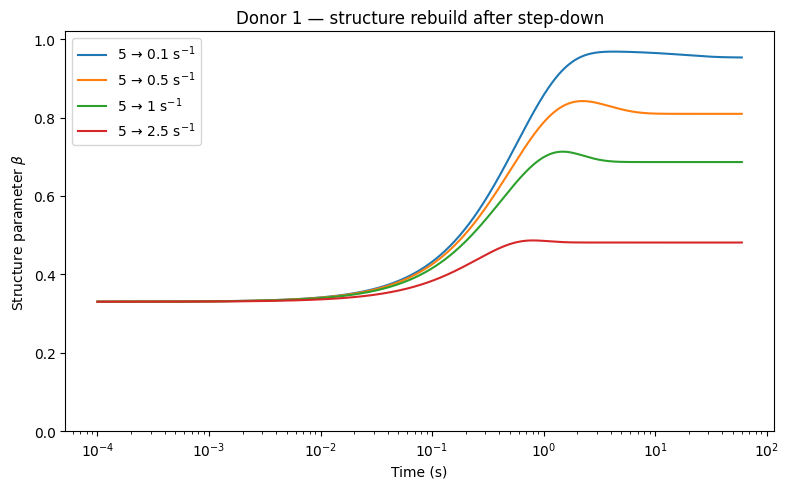

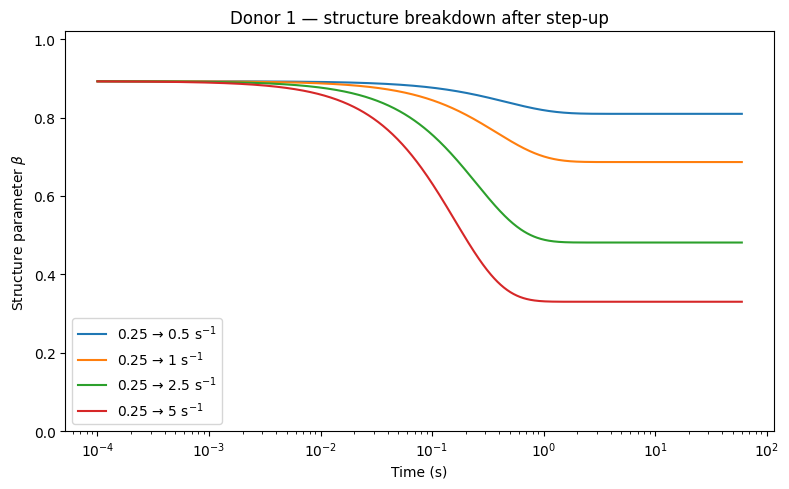

In [17]:

plt.figure(figsize=(8, 5))
for (protocol, initial_rate, final_rate), sim in step_simulations.items():
    if protocol != "step_down":
        continue
    q = sim[sim["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"{initial_rate:g} → {final_rate:g} s$^{{-1}}$")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — structure rebuild after step-down")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for (protocol, initial_rate, final_rate), sim in step_simulations.items():
    if protocol != "step_up":
        continue
    q = sim[sim["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"{initial_rate:g} → {final_rate:g} s$^{{-1}}$")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — structure breakdown after step-up")
plt.legend()
plt.tight_layout()
plt.show()


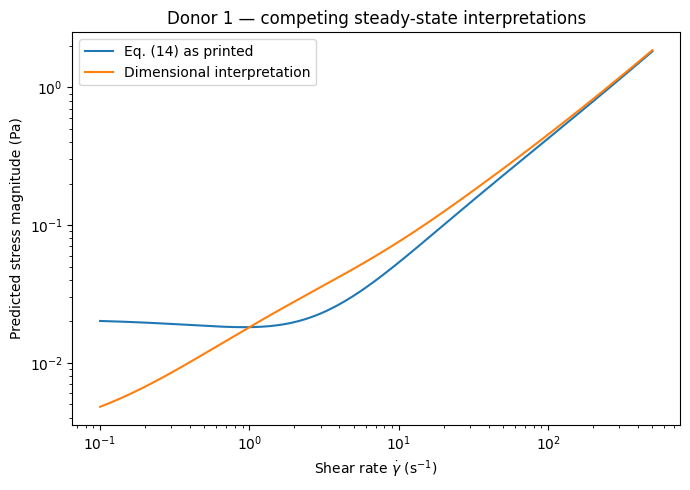

In [18]:

g_grid = np.logspace(-1, np.log10(500), 400)

plt.figure(figsize=(7, 5))
plt.loglog(
    g_grid,
    np.abs(steady_total_stress_as_printed(g_grid, P1)),
    label="Eq. (14) as printed"
)
plt.loglog(
    g_grid,
    np.abs(steady_total_stress_dimensional(g_grid, P1)),
    label="Dimensional interpretation"
)
plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel("Predicted stress magnitude (Pa)")
plt.title("Donor 1 — competing steady-state interpretations")
plt.legend()
plt.tight_layout()
plt.show()
